## **Praktikum Sistem Komunikasi Multimedia/Sistem dan Teknologi Multimedia**



---



* Nama: Kayla Puteri Gunawan
* NIM: 211331010
* Kelas: 3A - TTE


## Modul 7: ELIAS GAMMA & ELIAS DELTA - BAGIAN DECODER

# Instruksi!

Sebelum melakukan pekerjaan di bawah, ada beberapa hal yang harus diperhatikan.

* Waktu pengerjaan sesuai dengan deadline pada GCR.
* GCR akan ditutup setelah jam tersebut.
* Waktu submit ke GCR berpengaruh pada nilai, lebih cepat akan mendapat nilai tambahan.
* Jika ada kendala saat upload file ipynb, maka bisa dengan menyematkan link google collabnya pada kolom submission tugas di GCR.
* Jika ada pertanyaan bisa diajukan di grup perkuliahan.

*selamat mengerjakan*

### Pendahuluan

**Elias Gamma Coding**

Metode ini dikembangkan oleh Peter Elias. Dengan teknik pengkodean:
1. Tulis dalam biner
2. Jumlah bit pada proses no.1 dikurang satu untuk menentukan jumlah nol (zeros) yang
harus ditambahkan di muka angka tersebut.
Contoh ada sebuat bilangan 11:
1. Langkah pertama adalah konversi 11 menjadi biner, yakni 1011.
2. Cari jumlah bit/pangkat tertinggi pada proses pertama, lalu kurangi 1.

Gunakan jumlah tersebut untuk menambahkan angka 0 didepan biner yang terdapat pada proses pertama.
Hasilnya adalah 0001011.

Sehingga jika didapatkan deretan angka 11, 15, dan 27 maka dengan elias gamma code deretan angka tersebut dapat diubah menjadi 00010110001111000011011.

Fungsi dari elias gamma code ini adalah pengguna dapat mengirim banyak angka berjajar sekaligus, sebab jika kita hanya mengubah bilangan tersebut menjadi biner maka akan sulit melakukan decode.

Sebagai contoh tiga bilangan yang terdapat pada contoh di atas. Jika data
tersebut dikirim 1011111111011 saja, maka akan ada banyak variasi kombinasi biner untuk mendapatkan nilai desimalnya.

Untuk bagian decoder proses yang harus dilakukan adalah :
1. Menghitung jumlah nol sebelum ditemukan bilangan 1.
2. Lalu jumlah nol tadi ditambahkan 1, maka angka hasil penjumlahan tersebut merupakan jumlah bit yang harus dikonversikan ke desimal.

Contoh pada biner 0001011. Langkah pertama adalah menghitung angka nol di awal, sehingga didapatkan nilai 3. Nilai 3 tersebut ditambahkan 1 menjadi 4, artinya 4 bit setelah deretan 0 harus dikonversikan menjadi desimal. Didapat biner 1001 atau jika dikonversikan ke dalam desimal menjadi 11.



---



**Elias Delta Coding & Decoding**

Seperti Elias Gamma, kode ini ditemukan oleh Peter Elias. Kode ini menerapkan juga metode
pada gamma coding, terutama di bagian kepala. Tekniknya adalah sebagai berikut:
1. Cari pangkat tertinggi binernya, misalnya desimal 11 jika dibinerkan menjadi 1011 dimana
pangkat tertingginya adalah 3. Jadi N’=3.
2. Gunakan Gamma Coding untuk mengkodekan bilangan N dimana N=N’+1. Jadi untuk
kasus desimal 11 maka kita harus membuat Gamma Coding dari 4 yaitu 00100.
3. Tambahkan sisa N’ binary pada hasil no.2. Jadi diperoleh jawaban 00100011.
Jika diberikan deretan angka 35, 101, dan 112, maka akan didapatkan output dengan metode Elias Delta Code sebagai berikut:

00110000110011110010100111110000

Berikutnya adalah melakukan decode menggunakan Elias Delta Coding, prinsipnya adalaH kebalikan dari langkah satu sampai tiga di atas. Misalnya kita akan mendekode 00100011.

1. Temukan jumlah zero sebelum ditemukan angka satu, yaitu 00 atau berjumlah 2 bit. Berarti ada (2+1) angka yang harus diperhatikan setelah dua angka nol ini, yaitu 100. DiMana angka 100 jika dikonversikan dalam desimalnya berarti 4, jadi kita mendapatkan N’ dengan N-1 atau 4-1 = 3.
2. Jika N’ telah diketahui (yaitu 3) maka ada 3 bit tersisa yang menjadi bagian bilangan itu yakni 011. Jadi diperoleh jawaban 1011 (ditambahkan digit 1 di depan biner sebelumnya) yang artinya 11.


---

### Langkah-langkah Percobaan

1. Buatlah program decoder dengan metode Elias Gamma Code untuk mengembalikan data yang dihasilkan pada praktikum sebelumnya.
2. Lakukan juga proses decoder pada hasil yang didapat dari encoder dengan metode Elias Delta Code sebelumnya.
3. Lampirkan flowchart, program dan screenshot hasil pada laporan yang dibuat.

**Instruksi:**





In [1]:
def GammaDecode(input):  # Mendefinisikan fungsi untuk mendekode data gamma
 i = 0  # Inisialisasi variabel i dengan nilai 0
 N = 1  # Inisialisasi variabel N dengan nilai 1
 gammaResult = []  # Inisialisasi list gammaResult untuk menyimpan hasil dekode gamma

 while i < len(input):  # Melakukan perulangan selama i kurang dari panjang input
  if input[i] == "1":  # Jika karakter pada posisi i adalah "1"
    gammaResult.append(int(input[i:i+N], 2))  # Mengubah substring dari i hingga i+N menjadi bilangan desimal dan menambahkannya ke gammaResult
    i = i + N  # Menambahkan nilai i dengan N
    N = 1  # Mengembalikan nilai N ke 1
  i = i + 1  # Menambah nilai i dengan 1
  N = N + 1  # Menambah nilai N dengan 1
 return gammaResult  # Mengembalikan hasil dekode gamma dalam bentuk list

def DeltaDecode(input):  # Mendefinisikan fungsi untuk mendekode data delta
  i = 0  # Inisialisasi variabel i dengan nilai 0
  N = 1  # Inisialisasi variabel N dengan nilai 1
  deltaResult = []  # Inisialisasi list deltaResult untuk menyimpan hasil dekode delta

  while i < len(input):  # Melakukan perulangan selama i kurang dari panjang input
    if input[i] == "1":  # Jika karakter pada posisi i adalah "1"
      x = int(input[i:i+N], 2) - 1  # Mengubah substring dari i hingga i+N menjadi bilangan desimal dan mengurangkan 1, hasilnya disimpan dalam variabel x
      delta_bin = '1' + input[i+N:i+N+x]  # Membuat string delta_bin dengan menambahkan '1' di depan substring dari i+N hingga i+N+x
      delta_dec = int(delta_bin, 2)  # Mengubah delta_bin menjadi bilangan desimal dan menyimpannya dalam variabel delta_dec
      i = i + N + x  # Menambah nilai i dengan N dan x
      N = 1  # Mengembalikan nilai N ke 1
      deltaResult.append(delta_dec)  # Menambahkan hasil dekode delta ke deltaResult
    i = i + 1  # Menambah nilai i dengan 1
    N = N + 1  # Menambah nilai N dengan 1
  return deltaResult  # Mengembalikan hasil dekode delta dalam bentuk list

data_gamma = "00001011100000100011000001001000000010110000000101101"  # Data gamma yang akan didekode
data_delta = "0010101110011000011001100010000110011000011001101"  # Data delta yang akan didekode

Decoding_gamma = GammaDecode(data_gamma)  # Mendekode data gamma
Decoding_delta = DeltaDecode(data_delta)  # Mendekode data delta

print('input gamma: \n\t', data_gamma)  # Menampilkan data gamma input
print('gamma decoding: \n\t', Decoding_gamma)  # Menampilkan hasil dekode gamma
print('input delta: \n\t', data_delta)  # Menampilkan data delta input
print('delta decoding: \n\t', Decoding_delta)  # Menampilkan hasil dekode delta


input gamma: 
	 00001011100000100011000001001000000010110000000101101
gamma decoding: 
	 [23, 35, 36, 44, 45]
input delta: 
	 0010101110011000011001100010000110011000011001101
delta decoding: 
	 [23, 35, 36, 44, 45]




> Analisa dari program di atas:

Program di atas adalah contoh implementasi decoding Gamma dan Delta untuk mendekode data yang dienkripsi menggunakan teknik run-length encoding. Fungsi GammaDecode mengurai run-length encoding Gamma, sedangkan fungsi DeltaDecode mengurai run-length encoding Delta. Kedua fungsi ini menggunakan loop untuk membaca bit dalam input dan memahami panjang run-length encoding saat ini. Hasil decoding disimpan dalam list dan kemudian dicetak. Program ini memungkinkan pengguna untuk mengurai data yang dienkripsi dengan metode Gamma dan Delta, dan analisis dari hasil decoding dapat digunakan untuk menginterpretasi data asli yang dienkripsi.








Lampirkan gambar flowchart di bawah ini:

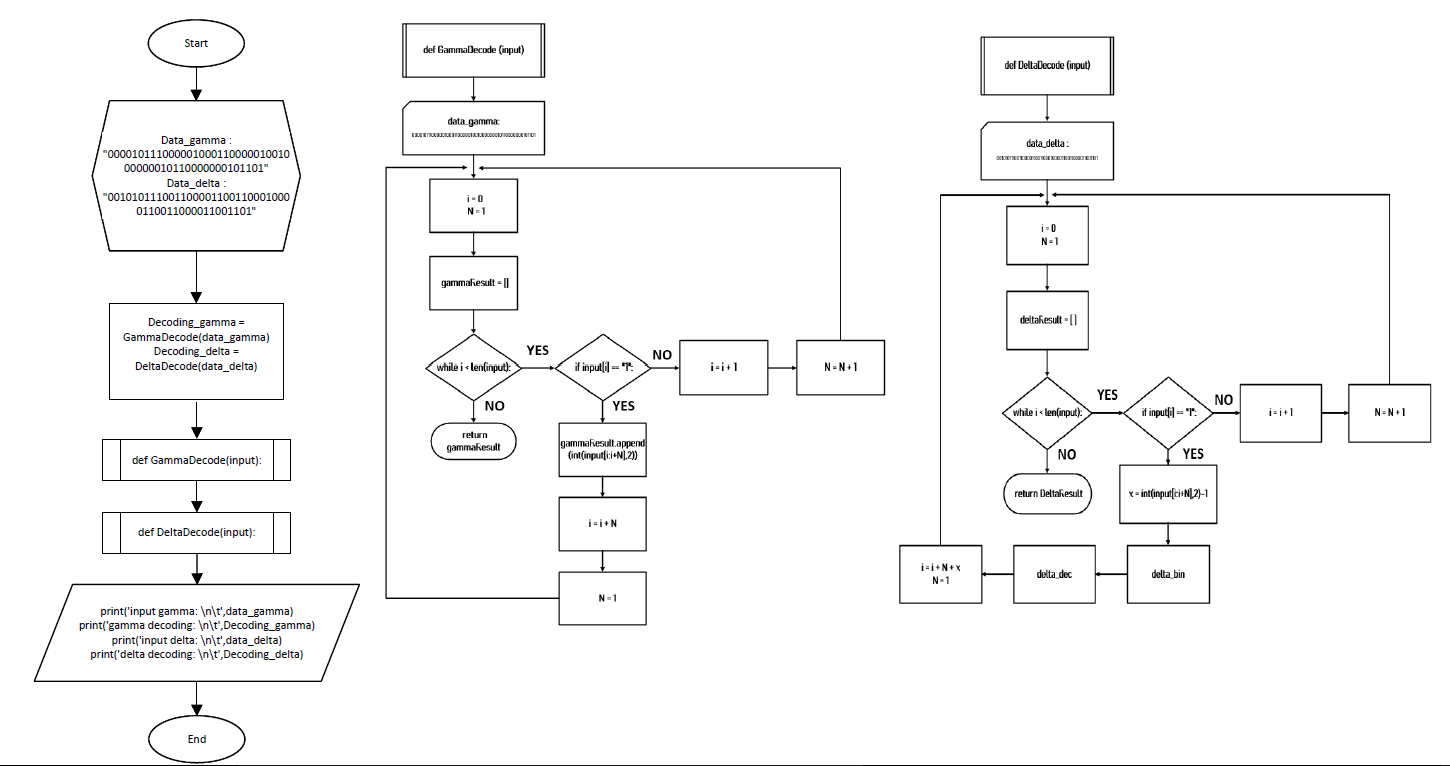



---




© Prof. Hertog Nugroho & Muhammad Yusuf Fadhlan, SST., M.Sc.

Politeknik Negeri Bandung (2023)